## Assignment 1: Data Profiling
### Group Member:
1. AHMAD IRFAN FAIZI BIN MOHD YUSRI (A211206)
2. MUHAMMAD ZAHIN HANAFI BIN ROSGAIDDIN (A211415)
3. MUHAMMAD NAUFAK RIZQI AULIYA (A222945)
4. ZUL RIZA BIN IDRIS (A212679)


### SCENARIO
PropertyWise, a consulting company which help customer identify potential residential property investment opportunities in Hulu Langat, Selangor by using property transaction data obtained from the National Property Information Centre (NAPIC), Malaysia. Before using the dataset, the consultancy needs to evaluate its quality and identify issues that could affect the reliability of subsequent analysis.

### Business Question
Is the dataset that obtained from NAPIC is consistent and accurate enough to be used in property transaction analysis?

### Data Source
Source: National Property Information Centre, NAPIC
URL: https://napic.jpph.gov.my/ms/data-transaksi?category=36&id=241





### Data Profiling and Issue Handling
Initial data profiling was conducted to understand the dataset's structure and assess the completeness of its attributes. The analysis examines data types, non-null records and unique values to identify potential data quality issues that require further investigation.

In [469]:
import os
import pandas as pd

# Load the NAPIC property transaction dataset
df = pd.read_csv(
    "../data/Dataset_PropWise1.csv",
    encoding="utf-16",
    sep="\t"
)

# Initial inspection of the NAPIC dataset

print("Dataset Overview")
print("-----------------")
print("Total records:", df.shape[0])
print("Total columns:", df.shape[1])

# Display the first five records

display(df.head())

# Display all column names

print("Dataset Columns:")
for column in df.columns:
    print("-", repr(column))



Dataset Overview
-----------------
Total records: 1845
Total columns: 14


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Unit,Main Floor Area,Unit,Unit Level,Transaction Price,Unnamed: 13
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,,April 2026,Leasehold,70.0,sq.m,-,-,1,"RM267,000.00",NaN
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATok AHMAD RAZALI,,April 2026,Leasehold,85.0,sq.m,-,-,G,"RM400,000.00",NaN
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,April 2026,Leasehold,107.0,sq.m,-,-,2,"RM450,000.00",NaN
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,May 2026,Leasehold,100.0,sq.m,-,-,1,"RM390,000.00",NaN
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,,August 2025,Leasehold,82.0,sq.m,-,-,4&5,"RM330,000.00",NaN


Dataset Columns:
- 'Property Type'
- 'District'
- 'Mukim'
- 'Scheme Name/Area'
- 'Road Name'
- 'Month, Year of Transaction Date'
- 'Tenure'
- 'Land/Parcel Area'
- 'Unit'
- 'Main Floor Area'
- 'Unit        '
- 'Unit Level'
- 'Transaction Price  '
- 'Unnamed: 13'


In [470]:
profile = pd.DataFrame({
    "Column": df.columns,
    "Data Type": df.dtypes.astype(str).values,
    "Non-Null Count": df.notna().sum().values,
    "Unique Values": df.nunique().values
})

display(profile)

,Column,Data Type,Non-Null Count,Unique Values
0,Property Type,str,1845,1
1,District,str,1840,1
2,Mukim,str,1845,17
3,Scheme Name/Area,str,1845,221
4,Road Name,str,1845,1
5,"Month, Year of Transaction Date",str,1845,30
6,Tenure,str,1845,2
7,Land/Parcel Area,float64,1845,198
8,Unit,str,1845,1
9,Main Floor Area,str,1845,1


In [471]:
import numpy as np

df_clean = df.copy()

# Convert empty strings and whitespace-only values to NaN
df_clean = df_clean.replace(
    r"^\s*$",
    np.nan,
    regex=True
)

# Convert hyphen placeholders to NaN
df_clean = df_clean.replace("-", np.nan)

print("Missing-value placeholders converted to NaN.")

Missing-value placeholders converted to NaN.


In [472]:
missing_table = pd.DataFrame({
    "Column": df_clean.columns,
    "Missing Count": df_clean.isnull().sum().values,
    "Missing Percentage": (
        df_clean.isnull().mean().values * 100
    ).round(2)
})

missing_table = missing_table.sort_values(
    "Missing Count",
    ascending=False
)

display(missing_table)

,Column,Missing Count,Missing Percentage
4,Road Name,1845,100.00
9,Main Floor Area,1845,100.00
10,Unit,1845,100.00
13,Unnamed: 13,1845,100.00
1,District,5,0.27
0,Property Type,0,0.00
5,"Month, Year of Transaction Date",0,0.00
3,Scheme Name/Area,0,0.00
2,Mukim,0,0.00
6,Tenure,0,0.00


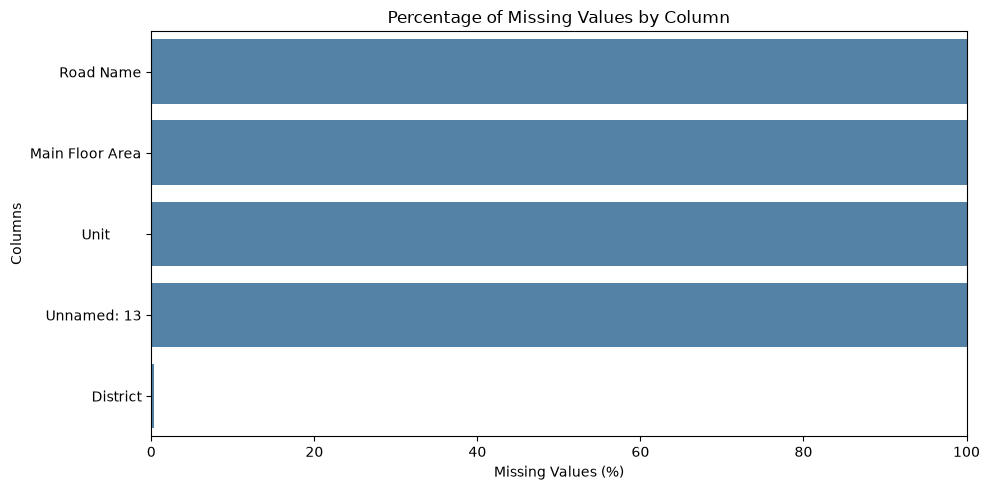

In [473]:
import matplotlib.pyplot as plt
import seaborn as sns

missing_plot = missing_table[
    missing_table["Missing Count"] > 0
]

plt.figure(figsize=(10, 5))

sns.barplot(
    data=missing_plot,
    x="Missing Percentage",
    y="Column",
    color="steelblue"
)

plt.title("Percentage of Missing Values by Column")
plt.xlabel("Missing Values (%)")
plt.ylabel("Columns")
plt.xlim(0, 100)
plt.tight_layout()
plt.show()

### Data Profiling Finding
The initial data profiling examined the dataset's structure, data types, unique values and completeness across 1,845 records and 14 columns. The analysis identified potential data quality issues involving missing values and column structure.

The missing-value analysis revealed that **four columns had 100% missing values**, affecting all 1,845 records. These columns were Road Name, Main Floor Area, Unit and Unnamed: 13. The remaining columns showed 0% missing values based on the current profiling results.

The initial profiling also identified an unnamed column with no non-null values and two columns labelled [Unit]. These findings indicate potential structural issues that require further investigation. In addition, several categorical attributes, including Property Type, District and Road Name, had only one unique value in the initial profiling results, which may indicate limited variation or missing information.

Overall, the results highlight potential completeness and structural issues that should be investigated before the dataset is used for further analysis. The next stage will verify the affected columns and examine other data quality issues, including invalid values, inconsistencies and potential outliers, before determining the appropriate data cleaning methods.


In [474]:
import numpy as np
import pandas as pd

print("DATA CLEANING & OTHER QUALITY ISSUES")

# Preserve the original dataset
df_clean = df.copy()

# Remove leading and trailing spaces from column names
df_clean.columns = df_clean.columns.str.strip()

# Rename duplicate Unit columns by position
cols = list(df_clean.columns)
cols[8] = "Land Area Unit"
cols[10] = "Main Floor Unit"
df_clean.columns = cols

print("Working copy created.")
print("Original dataset shape:", df.shape)
print("Working dataset shape:", df_clean.shape)

display(df_clean.head())

DATA CLEANING & OTHER QUALITY ISSUES
Working copy created.
Original dataset shape: (1845, 14)
Working dataset shape: (1845, 14)


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price,Unnamed: 13
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,,April 2026,Leasehold,70.0,sq.m,-,-,1,"RM267,000.00",NaN
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATok AHMAD RAZALI,,April 2026,Leasehold,85.0,sq.m,-,-,G,"RM400,000.00",NaN
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,April 2026,Leasehold,107.0,sq.m,-,-,2,"RM450,000.00",NaN
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,,May 2026,Leasehold,100.0,sq.m,-,-,1,"RM390,000.00",NaN
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,,August 2025,Leasehold,82.0,sq.m,-,-,4&5,"RM330,000.00",NaN


In [475]:
print("1. Fixing Invalid Values:")

# Remove the unnamed column if it is entirely empty
if "Unnamed: 13" in df_clean.columns:
    if df_clean["Unnamed: 13"].isna().all():
        df_clean = df_clean.drop(columns=["Unnamed: 13"])
        print("Removed the completely empty Unnamed: 13 column.")

# Convert blank strings and selected placeholders into NaN
for col in df_clean.select_dtypes(include=["object", "string"]).columns:
    df_clean[col] = df_clean[col].replace(
        r"^\s*$",
        np.nan,
        regex=True
    )

    df_clean[col] = df_clean[col].replace(
        ["-", "nan", "NAN"],
        np.nan
    )

print("Converted blank strings and selected placeholders to NaN.")

display(df_clean.head())

1. Fixing Invalid Values:
Removed the completely empty Unnamed: 13 column.
Converted blank strings and selected placeholders to NaN.


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,NaN,NaN,1,"RM267,000.00"
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATok AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,NaN,NaN,G,"RM400,000.00"
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,NaN,NaN,2,"RM450,000.00"
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,NaN,NaN,1,"RM390,000.00"
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,NaN,NaN,4&5,"RM330,000.00"


In [476]:
print("Original Main Floor Area:")
print(df["Main Floor Area"].head(10))

print("\nCleaned Main Floor Area:")
print(df_clean["Main Floor Area"].head(10))

print("\nMissing values before cleaning:",
      df["Main Floor Area"].isna().sum())

print("Missing values after cleaning:",
      df_clean["Main Floor Area"].isna().sum())

Original Main Floor Area:
0    -
1    -
2    -
3    -
4    -
5    -
6    -
7    -
8    -
9    -
Name: Main Floor Area, dtype: str

Cleaned Main Floor Area:
0    NaN
1    NaN
2    NaN
3    NaN
4    NaN
5    NaN
6    NaN
7    NaN
8    NaN
9    NaN
Name: Main Floor Area, dtype: str

Missing values before cleaning: 0
Missing values after cleaning: 1845


In [477]:
print("Original column count:", len(df.columns))
print("Cleaned column count:", len(df_clean.columns))

print("\nNew columns:")
print(sorted(set(df_clean.columns) - set(df.columns)))

print("\nRemoved columns:")
print(sorted(set(df.columns) - set(df_clean.columns)))

Original column count: 14
Cleaned column count: 13

New columns:
['Land Area Unit', 'Main Floor Unit', 'Transaction Price']

Removed columns:
['Transaction Price  ', 'Unit', 'Unit        ', 'Unnamed: 13']


In [478]:
print("2. Fixing Inconsistent Formats:")

# Standardise spacing in text columns
text_cols = df_clean.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df_clean[col] = df_clean[col].apply(
        lambda x: " ".join(x.split()) if isinstance(x, str) else x
    )

# Standardise selected abbreviations in Scheme Name/Area
if "Scheme Name/Area" in df_clean.columns:
    df_clean["Scheme Name/Area"] = (
        df_clean["Scheme Name/Area"]
        .str.upper()
        .str.replace(r"\bTMN\b", "TAMAN", regex=True)
        .str.replace(r"\bJLN\b", "JALAN", regex=True)
    )

print("Standardised spacing and selected abbreviations.")

print(
    "Unique Scheme Names/Areas:",
    df_clean["Scheme Name/Area"].nunique()
)

display(df_clean.head())

2. Fixing Inconsistent Formats:
Standardised spacing and selected abbreviations.
Unique Scheme Names/Areas: 198


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,NaN,NaN,1,"RM267,000.00"
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,NaN,NaN,G,"RM400,000.00"
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,NaN,NaN,2,"RM450,000.00"
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,NaN,NaN,1,"RM390,000.00"
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,NaN,NaN,4&5,"RM330,000.00"


In [479]:
print("3. Fixing Wrong Data Types:")

# Convert land/parcel area to numeric
df_clean["Land/Parcel Area"] = pd.to_numeric(
    df_clean["Land/Parcel Area"]
    .astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# Convert main floor area to numeric
df_clean["Main Floor Area"] = pd.to_numeric(
    df_clean["Main Floor Area"]
    .astype("string")
    .str.replace(",", "", regex=False),
    errors="coerce"
)

# Convert transaction price to numeric
df_clean["Transaction Price"] = pd.to_numeric(
    df_clean["Transaction Price"]
    .astype("string")
    .str.replace("RM", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip(),
    errors="coerce"
)

# Convert transaction month/year into a date
df_clean["Transaction Date"] = pd.to_datetime(
    df_clean["Month, Year of Transaction Date"],
    format="%B %Y",
    errors="coerce"
)

print("Data type conversion completed.")


print(
    df_clean[
        [
            "Land/Parcel Area",
            "Main Floor Area",
            "Transaction Price",
            "Transaction Date"
        ]
    ].dtypes
)

display(df_clean.head())


3. Fixing Wrong Data Types:
Data type conversion completed.
Land/Parcel Area            Float64
Main Floor Area             Float64
Transaction Price           Float64
Transaction Date     datetime64[us]
dtype: object


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price,Transaction Date
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,<NA>,NaN,1,267000.0,2026-04-01
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,<NA>,NaN,G,400000.0,2026-04-01
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,<NA>,NaN,2,450000.0,2026-04-01
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,<NA>,NaN,1,390000.0,2026-05-01
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,<NA>,NaN,4&5,330000.0,2025-08-01


In [480]:
print("4. Handling Duplicates:")

rows_before = len(df_clean)

duplicate_count = df_clean.duplicated().sum()

print("Duplicate rows detected:", duplicate_count)

df_clean = df_clean.drop_duplicates(
    keep="first"
).reset_index(drop=True)

rows_after = len(df_clean)

print("Duplicate rows removed:", rows_before - rows_after)
print("Rows remaining:", rows_after)

display(df_clean.head())

4. Handling Duplicates:
Duplicate rows detected: 2
Duplicate rows removed: 2
Rows remaining: 1843


,Property Type,District,Mukim,Scheme Name/Area,Road Name,"Month, Year of Transaction Date",Tenure,Land/Parcel Area,Land Area Unit,Main Floor Area,Main Floor Unit,Unit Level,Transaction Price,Transaction Date
0,Condominium/Apartment,Hulu Langat,Ampang,TAMAN BUKIT SEGAR EMAS/CHERAS HARTAMAS,NaN,April 2026,Leasehold,70.0,sq.m,<NA>,NaN,1,267000.0,2026-04-01
1,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,85.0,sq.m,<NA>,NaN,G,400000.0,2026-04-01
2,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,April 2026,Leasehold,107.0,sq.m,<NA>,NaN,2,450000.0,2026-04-01
3,Condominium/Apartment,Hulu Langat,Ampang,TAMAN DATOK AHMAD RAZALI,NaN,May 2026,Leasehold,100.0,sq.m,<NA>,NaN,1,390000.0,2026-05-01
4,Condominium/Apartment,Hulu Langat,Ampang,TAMAN PANDAN INDAH,NaN,August 2025,Leasehold,82.0,sq.m,<NA>,NaN,4&5,330000.0,2025-08-01


In [481]:
print("OUTLIER DETECTION & HANDLING")

num_cols = [
    "Transaction Price",
    "Land/Parcel Area",
    "Main Floor Area"
]

outlier_stats = []

for col in num_cols:
    s = df_clean[col].dropna()

    if len(s) == 0:
        print(f"Skipping {col}: no valid numeric values.")
        continue

    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1

    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr

    iqr_outliers = int(
        ((s < lower_bound) | (s > upper_bound)).sum()
    )

    std = s.std()

    if std > 0:
        z_outliers = int(
            (((s - s.mean()) / std).abs() > 3).sum()
        )
    else:
        z_outliers = 0

    outlier_stats.append({
        "Column": col,
        "Q1": round(q1, 2),
        "Median": round(s.median(), 2),
        "Q3": round(q3, 2),
        "IQR": round(iqr, 2),
        "Lower Fence": round(lower_bound, 2),
        "Upper Fence": round(upper_bound, 2),
        "IQR Outliers": iqr_outliers,
        "IQR Outlier (%)": round(
            iqr_outliers / len(s) * 100, 2
        ),
        "Z-Score Outliers": z_outliers
    })

outlier_summary_df = pd.DataFrame(outlier_stats)

display(outlier_summary_df)

OUTLIER DETECTION & HANDLING
Skipping Main Floor Area: no valid numeric values.


,Column,Q1,Median,Q3,IQR,Lower Fence,Upper Fence,IQR Outliers,IQR Outlier (%),Z-Score Outliers
0,Transaction Price,280000.0,350000.0,448000.0,168000.0,28000.0,700000.0,45,2.44,23
1,Land/Parcel Area,82.0,92.0,106.0,24.0,46.0,142.0,112,6.08,22


In [482]:
print("INVESTIGATING POTENTIALLY INVALID RECORDS")

# Property categories that may represent strata properties
strata_types = [
    "Condominium/Apartment",
    "Flat",
    "Low-Cost Flat",
    "Town House"
]

is_strata = df_clean["Property Type"].isin(strata_types)

# Potentially implausible floor area
corrupted_floor = (
    df_clean["Main Floor Area"].notna()
    & (~is_strata)
    & (
        (df_clean["Main Floor Area"] > 3000)
        | (
            df_clean["Main Floor Area"]
            > df_clean["Land/Parcel Area"] * 5
        )
    )
)

# Potentially unusual land area for non-strata properties
small_land_area = (
    df_clean["Land/Parcel Area"].notna()
    & (~is_strata)
    & (df_clean["Land/Parcel Area"] < 30)
)

# Potentially misclassified low-cost property records
low_cost_types = [
    "Low-Cost Flat",
    "Low-Cost House"
]

potentially_misclassified = (
    df_clean["Property Type"].isin(low_cost_types)
    & (
        (df_clean["Transaction Price"] > 1_000_000)
        | (df_clean["Land/Parcel Area"] > 500)
    )
)

print("Potentially unusual floor area:", corrupted_floor.sum())
print("Potentially unusual land area:", small_land_area.sum())
print(
    "Potentially misclassified low-cost records:",
    potentially_misclassified.sum()
)

INVESTIGATING POTENTIALLY INVALID RECORDS
Potentially unusual floor area: 0
Potentially unusual land area: 0
Potentially misclassified low-cost records: 0


In [483]:
def flag_iqr(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1

    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr

    return (series < lower) | (series > upper)


df_clean["Is_Price_Outlier"] = (
    df_clean.groupby("Property Type")["Transaction Price"]
    .transform(flag_iqr)
    .fillna(False)
    .astype(bool)
)

print(
    "Potential price outliers flagged:",
    df_clean["Is_Price_Outlier"].sum()
)

display(
    df_clean.loc[
        df_clean["Is_Price_Outlier"],
        [
            "Property Type",
            "Transaction Price",
            "Is_Price_Outlier"
        ]
    ].head(10)
)

Potential price outliers flagged: 45


,Property Type,Transaction Price,Is_Price_Outlier
118,Condominium/Apartment,750000.0,True
225,Condominium/Apartment,840000.0,True
262,Condominium/Apartment,800000.0,True
606,Condominium/Apartment,735000.0,True
974,Condominium/Apartment,810000.0,True
1000,Condominium/Apartment,715000.0,True
1029,Condominium/Apartment,860000.0,True
1094,Condominium/Apartment,809000.0,True
1154,Condominium/Apartment,1476000.0,True
1163,Condominium/Apartment,900000.0,True


In [484]:
def cap_prices(series):
    lower = series.quantile(0.01)
    upper = series.quantile(0.99)

    return series.clip(
        lower=lower,
        upper=upper
    )


df_clean["Transaction Price (Capped)"] = (
    df_clean.groupby("Property Type")["Transaction Price"]
    .transform(cap_prices)
)

print("Original and capped transaction prices:")

display(
    df_clean[
        [
            "Property Type",
            "Transaction Price",
            "Transaction Price (Capped)",
            "Is_Price_Outlier"
        ]
    ].head(10)
)

Original and capped transaction prices:


,Property Type,Transaction Price,Transaction Price (Capped),Is_Price_Outlier
0,Condominium/Apartment,267000.0,267000.0,False
1,Condominium/Apartment,400000.0,400000.0,False
2,Condominium/Apartment,450000.0,450000.0,False
3,Condominium/Apartment,390000.0,390000.0,False
4,Condominium/Apartment,330000.0,330000.0,False
5,Condominium/Apartment,290000.0,290000.0,False
6,Condominium/Apartment,250000.0,250000.0,False
7,Condominium/Apartment,350000.0,350000.0,False
8,Condominium/Apartment,315000.0,315000.0,False
9,Condominium/Apartment,280000.0,280000.0,False


In [486]:
before_after_df = pd.DataFrame({
    "Metric": [
        "Total rows",
        "Total columns",
        "Unique scheme names/areas",
        "Unique road names",
        "Transaction price data type",
        "Missing transaction prices",
        "Missing land/parcel areas",
        "Missing main floor areas"
    ],
    "Before Cleaning": [
        len(df),
        df.shape[1],
        df["Scheme Name/Area"].nunique(),
        df["Road Name"].nunique(),
        str(df["Transaction Price"].dtype)
            if "Transaction Price" in df.columns
            else "Column not found",
        df["Transaction Price"].isna().sum()
            if "Transaction Price" in df.columns
            else None,
        df["Land/Parcel Area"].isna().sum(),
        df["Main Floor Area"].isna().sum()
    ],
    "After Cleaning": [
        len(df_clean),
        df_clean.shape[1],
        df_clean["Scheme Name/Area"].nunique(),
        df_clean["Road Name"].nunique(),
        str(df_clean["Transaction Price"].dtype),
        df_clean["Transaction Price"].isna().sum(),
        df_clean["Land/Parcel Area"].isna().sum(),
        df_clean["Main Floor Area"].isna().sum()
    ]
})

display(before_after_df)

,Metric,Before Cleaning,After Cleaning
0,Total rows,1845,1843
1,Total columns,14,16
2,Unique scheme names/areas,221,198
3,Unique road names,1,0
4,Transaction price data type,Column not found,Float64
5,Missing transaction prices,None,0
6,Missing land/parcel areas,0,0
7,Missing main floor areas,0,1843


### Data Cleaning and Outlier Handling

The cleaning process addressed missing-value representations, inconsistent text formatting, data types and duplicate records. A separate working copy was used to preserve the original dataset.

Potential outliers were investigated using the Interquartile Range (IQR) and Z-score methods. Additional checks examined unusually large floor areas, small land areas and potentially misclassified property records.

Statistical outliers were not automatically treated as errors because unusually high or low property transaction values may be legitimate. Potentially invalid records should be reviewed against appropriate business rules before removal. Where capping is applied, the original transaction price is retained for traceability.

The before-and-after comparison summarises the changes made and the remaining data quality limitations.
